# Emometer: highlight emotion words (NRC EmoLex)

Same idea as `test.ipynb`, but instead of reading emotion features out of an SAE, every word is looked up in the [NRC Word-Emotion Association Lexicon (EmoLex)](https://saifmohammad.com/WebPages/NRC-Emotion-Lexicon.htm) and highlighted in the colour of the emotions it is associated with.

- **Lexicon:** EmoLex v0.92, ~14k English words, each tagged 0/1 for eight emotions (anger, anticipation, disgust, fear, joy, sadness, surprise, trust) plus positive/negative sentiment. It is downloaded on first run and cached next to the notebook.
- **Emotions shown:** joy, sadness, anger and fear, the four that `test.ipynb` uses and EmoLex also has. EmoLex has no *anxiety* category.

The associations are binary and context-free: a word either carries an emotion or it doesn't, regardless of negation or how it is used. A word can carry several emotions (e.g. *scream* is anger + fear); such words are striped with all of their colours. Hover a word to see its emotions. EmoLex lists base forms only, so inflected words (*screamed*, *slammed*, *smiles*) fall back to a crude suffix-stripped stem.

In [1]:
import html
import io
import re
import zipfile
from collections import defaultdict
from functools import cache
from pathlib import Path

import requests
from IPython.display import HTML, display

LEXICON_URL = "https://saifmohammad.com/WebDocs/Lexicons/NRC-Emotion-Lexicon.zip"
LEXICON_MEMBER = "NRC-Emotion-Lexicon/NRC-Emotion-Lexicon-Wordlevel-v0.92.txt"
LEXICON_PATH = Path("NRC-Emotion-Lexicon-Wordlevel-v0.92.txt")

# emotion -> highlight colour
EMOTIONS = {
    "joy":     "yellow",
    "sadness": "blue",
    "anger":   "red",
    "fear":    "purple",
}
TEXT_ON = {"yellow": "black", "orange": "black"}  # all other colours get white text

In [2]:
@cache
def lexicon() -> dict[str, frozenset[str]]:
    """word -> set of EmoLex emotions associated with it (only words with at least one)."""
    if not LEXICON_PATH.exists():
        # the server rejects requests' default User-Agent with a 406
        resp = requests.get(LEXICON_URL, headers={"User-Agent": "curl/8.7.1"}, timeout=120)
        resp.raise_for_status()
        archive = zipfile.ZipFile(io.BytesIO(resp.content))
        LEXICON_PATH.write_bytes(archive.read(LEXICON_MEMBER))

    emotions = defaultdict(set)
    for line in LEXICON_PATH.read_text(encoding="utf-8").splitlines():
        word, emotion, flag = line.split("\t")
        if flag == "1":
            emotions[word].add(emotion)
    return {w: frozenset(e) for w, e in emotions.items()}


# (suffix, replacement), tried in order when the exact word is not in the lexicon
_SUFFIXES = [("'s", ""), ("ies", "y"), ("ied", "y"), ("ing", ""), ("ing", "e"),
             ("ed", ""), ("ed", "e"), ("es", ""), ("s", ""), ("ly", "")]


def _lookup(word: str) -> frozenset[str]:
    lex = lexicon()
    word = word.lower().replace("’", "'")
    if word in lex:
        return lex[word]
    for suffix, repl in _SUFFIXES:
        stem = word[: -len(suffix)]
        if not word.endswith(suffix) or len(stem) < 3:
            continue
        # undouble the final consonant too: slammed -> slamm -> slam
        for candidate in (stem + repl, stem[:-1] if not repl and stem[-1] == stem[-2] else None):
            if candidate in lex:
                return lex[candidate]
    return frozenset()


def emotion_words(text: str) -> list[tuple[str, list[str]]]:
    """Split `text` into words and the text between them; return each piece with the shown emotions it carries."""
    pieces = re.split(r"([A-Za-z]+(?:['’][A-Za-z]+)*)", text)
    return [(p, [e for e in EMOTIONS if e in _lookup(p)] if i % 2 else []) for i, p in enumerate(pieces) if p]


def _span(text: str, colors: list[str] = (), title: str = "") -> str:
    style = "white-space:pre-wrap; padding:1px 0; border-radius:3px;"
    if colors:
        n = len(colors)
        stops = ", ".join(f"{c} {100 * i / n:.0f}% {100 * (i + 1) / n:.0f}%" for i, c in enumerate(colors))
        text_color = "black" if all(TEXT_ON.get(c) == "black" for c in colors) else "white"
        style += f" background:linear-gradient(to bottom, {stops}); color:{text_color};"
    return f'<span style="{style}" title="{html.escape(title)}">{html.escape(text)}</span>'


def highlight(text: str) -> None:
    pieces = []
    for piece, emotions in emotion_words(text):
        if not emotions:
            pieces.append(_span(piece))
            continue
        title = "EmoLex: " + ", ".join(sorted(_lookup(piece)))
        pieces.append(_span(piece, [EMOTIONS[e] for e in emotions], title))

    legend = " ".join(_span(f" {e} ", [color], f"EmoLex: {e}") for e, color in EMOTIONS.items())
    display(HTML(
        f'<div style="font-size:1.4em; line-height:2em;">{"".join(pieces)}</div>'
        f'<div style="font-size:0.85em; margin-top:0.5em;">{legend}</div>'
    ))

In [3]:
sentence = "Mia tore open the envelope and screamed with joy. She had won the scholarship. She ran home to tell her grandmother, but the house was silent. A note on the table said Grandma had been taken to the hospital. Mia’s joy collapsed into sadness. At the hospital, a nurse told her to wait outside for hours. Nobody would explain anything, and Mia’s anger rose until she slammed her fist against the wall. Then anxiety made her hands shake. What if Grandma never woke up? The door creaked open. A doctor stepped out, paused, and looked directly at Mia without smiling."

highlight(sentence)

## Figure 2: EmoLex arc over the story

The lexicon baseline for Figure 1 in `test.ipynb`. It reads the same story (`novel.txt`) and uses the same windows: the text is cut every `WINDOW_WORDS` words, where a word is anything between spaces. Each window's score is the share of its words that EmoLex associates with the emotion. Because a word is either tagged or not, there is no per-token value to normalize: the share is already in [0, 1].

Set `WINDOW_WORDS = 1000` for a coarser arc. The highest window is marked with the words around one of its tagged words, and the figure is saved to `figures/figure2.png`.

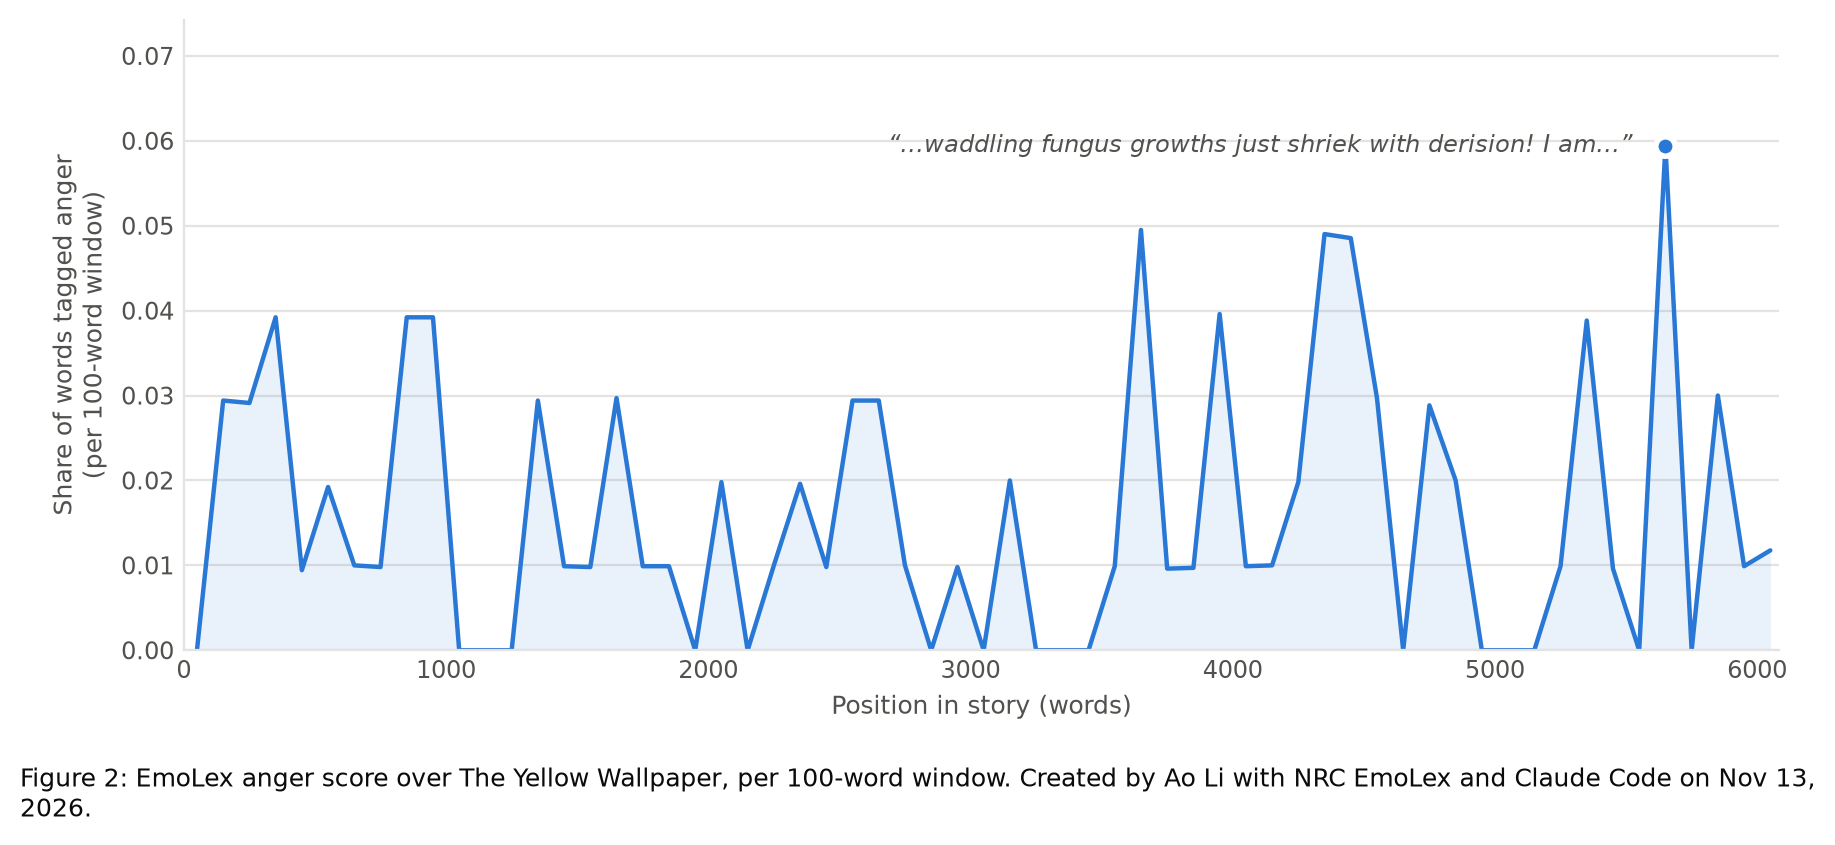

6085 words, 61 windows; 100 words tagged anger, in 44 windows
  words 5600-5700: 0.059
  words 3600-3700: 0.050
  words 4300-4400: 0.049
  words 4400-4500: 0.049
  words 3900-4000: 0.040


In [4]:
import json

import matplotlib.pyplot as plt

FIG_EMOTION = "anger"
STORY_NAME = "The Yellow Wallpaper"
STORY_PATH = Path("novel.txt")
WINDOW_WORDS = 100       # or 1000
CREATED_WITH = "NRC EmoLex and Claude Code"
FIG_DATE = "Nov 13, 2026"
FIG_PATH = Path("figures/figure2.png")
ARC_PATH = Path("arcs/emolex_arc.json")  # read by compare.ipynb

# Same look as Figure 1: one series, one hue; text and axes stay neutral.
LINE, INK, MUTED, RULE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"


def emolex_arc(text: str, emotion: str, window_words: int = WINDOW_WORDS):
    """Share of words tagged with `emotion` in consecutive windows of `window_words` words.

    Returns (window midpoints in words, window shares, words of the text, index of every tagged word).
    """
    words = text.split()
    n_windows = -(-len(words) // window_words)
    tagged, counted = [0] * n_windows, [0] * n_windows
    hits = []
    for i, word in enumerate(words):
        # A space-separated word can hold several letter-words ("angry—but"), so look each one up.
        for letters in re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)*", word):
            counted[i // window_words] += 1
            if emotion in _lookup(letters):
                tagged[i // window_words] += 1
                hits.append(i)
    shares = [t / c if c else 0.0 for t, c in zip(tagged, counted)]
    mids = [min(w * window_words + window_words / 2, len(words)) for w in range(n_windows)]
    return mids, shares, words, hits


story = STORY_PATH.read_text(encoding="utf-8")
mids, shares, words, hits = emolex_arc(story, FIG_EMOTION)
ARC_PATH.parent.mkdir(exist_ok=True)
ARC_PATH.write_text(json.dumps({
    "method": "emolex", "label": f"EmoLex {FIG_EMOTION}", "emotion": FIG_EMOTION, "story": STORY_NAME,
    "window_words": WINDOW_WORDS, "n_words": len(words), "mids": mids, "values": shares,
}, indent=1))

fig, ax = plt.subplots(figsize=(9, 3.8), dpi=200)
ax.fill_between(mids, shares, color=LINE, alpha=0.10, linewidth=0)
ax.plot(mids, shares, color=LINE, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")

# Mark the highest window with a quote around its middle tagged word.
peak = max(range(len(shares)), key=shares.__getitem__)
if shares[peak] > 0:
    in_peak = [i for i in hits if i // WINDOW_WORDS == peak]
    word = in_peak[len(in_peak) // 2]
    quote = " ".join(words[max(0, word - 4) : word + 5])
    ax.plot(mids[peak], shares[peak], "o", markersize=7, color=LINE, markeredgecolor="white", markeredgewidth=2, zorder=3)
    left = mids[peak] > len(words) / 2
    ax.annotate(
        f"“…{quote}…”", (mids[peak], shares[peak]), xytext=(-12 if left else 12, 0), textcoords="offset points",
        ha="right" if left else "left", va="center", fontsize=8.5, color=MUTED, style="italic",
    )

ax.set_xlim(0, len(words))
ax.set_ylim(0, max(shares) * 1.25 if max(shares) > 0 else 1)
ax.set_xlabel("Position in story (words)", color=MUTED, fontsize=9)
ax.set_ylabel(f"Share of words tagged {FIG_EMOTION}\n(per {WINDOW_WORDS}-word window)", color=MUTED, fontsize=9)
ax.grid(axis="y", color=RULE, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(RULE)
ax.tick_params(colors=MUTED, labelsize=8.5, length=0)

caption = (
    f"Figure 2: EmoLex {FIG_EMOTION} score over {STORY_NAME}, per {WINDOW_WORDS}-word window. "
    f"Created by Ao Li with {CREATED_WITH} on {FIG_DATE}."
)
fig.text(0.0, -0.02, caption, ha="left", va="top", fontsize=9, color=INK, wrap=True)
fig.tight_layout()

FIG_PATH.parent.mkdir(exist_ok=True)
fig.savefig(FIG_PATH, bbox_inches="tight", facecolor="white")
plt.show()

top = sorted(range(len(shares)), key=shares.__getitem__, reverse=True)[:5]
print(f"{len(words)} words, {len(shares)} windows; {len(hits)} words tagged {FIG_EMOTION}, in {sum(s > 0 for s in shares)} windows")
for w in top:
    print(f"  words {w * WINDOW_WORDS}-{min((w + 1) * WINDOW_WORDS, len(words))}: {shares[w]:.3f}")

## Figure 3: the same arc, normalized to [0, 1]

Figure 2 rescaled so its lowest window is 0 and its highest is 1: each share becomes (share − min) / (max − min). The shape doesn't change, only the y-axis, so this arc can sit on the same scale as other features' or stories' arcs. Saved to `figures/figure3.png`.

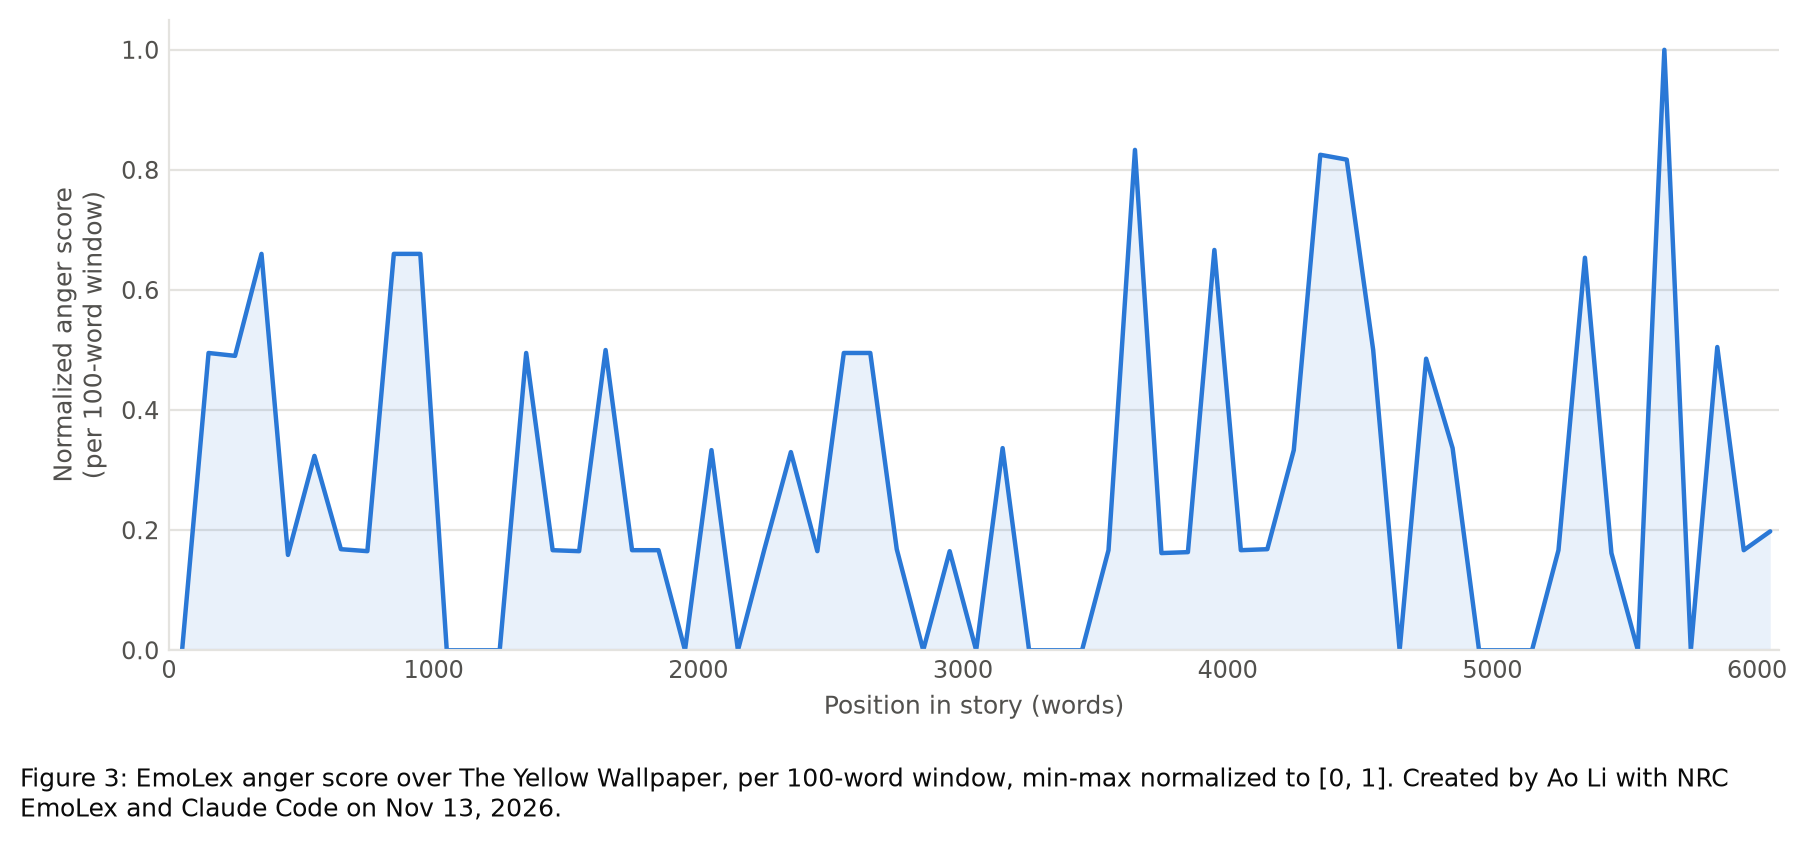

min share 0.000 -> 0, max share 0.059 -> 1


In [5]:
FIG3_PATH = Path("figures/figure3.png")

lo, hi = min(shares), max(shares)
normalized = [(s - lo) / (hi - lo) if hi > lo else 0.0 for s in shares]

fig, ax = plt.subplots(figsize=(9, 3.8), dpi=200)
ax.fill_between(mids, normalized, color=LINE, alpha=0.10, linewidth=0)
ax.plot(mids, normalized, color=LINE, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")

ax.set_xlim(0, len(words))
ax.set_ylim(0, 1.05)
ax.set_xlabel("Position in story (words)", color=MUTED, fontsize=9)
ax.set_ylabel(f"Normalized {FIG_EMOTION} score\n(per {WINDOW_WORDS}-word window)", color=MUTED, fontsize=9)
ax.grid(axis="y", color=RULE, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(RULE)
ax.tick_params(colors=MUTED, labelsize=8.5, length=0)

caption = (
    f"Figure 3: EmoLex {FIG_EMOTION} score over {STORY_NAME}, per {WINDOW_WORDS}-word window, "
    f"min-max normalized to [0, 1]. Created by Ao Li with {CREATED_WITH} on {FIG_DATE}."
)
fig.text(0.0, -0.02, caption, ha="left", va="top", fontsize=9, color=INK, wrap=True)
fig.tight_layout()

FIG3_PATH.parent.mkdir(exist_ok=True)
fig.savefig(FIG3_PATH, bbox_inches="tight", facecolor="white")
plt.show()

print(f"min share {lo:.3f} -> 0, max share {hi:.3f} -> 1")